# 07_02 Credible Intervals, Posterior Prediction and Bayesian A/B Decisions

**Learning objectives**
- Compute **credible intervals** (equal-tailed and **highest-density**) and read them as direct probability statements about the parameter.
- Derive and use the **posterior predictive distribution**: what the *next* observations will look like, with the parameter uncertainty included.
- Make a **Bayesian A/B decision** with $P(B>A)$, a **region of practical equivalence (ROPE)**, the **expected loss** and $P(\text{best})$ for several variants.
- Compare the Bayesian and frequentist answers on the real Cookie Cats data.

**Prerequisites:** [07_01 Bayesian updating](07_01_bayesian_updating_conjugates.ipynb), [06_07 A/B testing](../../module_06_inference/notebooks/06_07_ab_testing.ipynb) (the Cookie Cats data), [06_02 Confidence intervals](../../module_06_inference/notebooks/06_02_confidence_intervals.ipynb).

**Data.** `module_06_inference/data/cookie_cats.csv` (90,189 real players, source and license notes in that folder's README).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import pathlib
from scipy.optimize import minimize_scalar
pth = pathlib.Path('../../module_06_inference/data/cookie_cats.csv')
df = pd.read_csv(pth if pth.exists() else 'module_06_inference/data/cookie_cats.csv')

## 2. Prerequisite recap
The posterior of a rate after $x$ successes in $n$ trials under a Beta$(a,b)$ prior is Beta$(a+x,\,b+n-x)$ (07_01). A 95 % **confidence** interval is a statement about a procedure (06_02); here we want a statement about the parameter itself.

## 3. Intuition and story
The posterior is the full description of what we know. From it we can read **any** question as a probability: "what is the chance the conversion rate is above 12 %?", "what range contains the rate with probability 95 %?", "what is the chance variant B beats variant A?". It also tells us what to **expect next**: a prediction for tomorrow's data must include both the randomness of the data and our remaining uncertainty about the rate, so predictions are wider than "plug in the estimate". Finally, a decision needs more than a probability: how *much* do we lose if we choose wrong? The expected loss answers that.

## 4. Formal definitions

| Object | Definition |
|---|---|
| **Credible interval** | an interval $[l,u]$ with $P(l\le\theta\le u\mid x)=1-\alpha$ |
| **Equal-tailed interval** | $l,u$ are the $\alpha/2$ and $1-\alpha/2$ posterior quantiles |
| **Highest-density interval (HDI)** | the shortest interval with posterior mass $1-\alpha$; every point inside has higher density than every point outside |
| **Posterior predictive** | $p(\tilde x\mid x)=\int p(\tilde x\mid\theta)\,p(\theta\mid x)\,d\theta$ |
| **Beta-Binomial predictive** | for $\theta\mid x\sim\mathrm{Beta}(a',b')$ and $m$ new trials: $\tilde X\sim\mathrm{BetaBinomial}(m,a',b')$ |
| **ROPE** | a region $[-\epsilon,\epsilon]$ of effects too small to matter; decide using $P(\theta\in\mathrm{ROPE}\mid x)$ |
| **Expected loss** of choosing B | $E[\max(\theta_A-\theta_B,0)\mid x]$: the average amount we lose if B is actually worse |
| **$P(\text{best})$** | $P(\theta_k=\max_j\theta_j\mid x)$ for variant $k$ |

## 5. Derivations

### 5.1 Beta-Binomial predictive
$P(\tilde X=k\mid x)=\int_0^1\binom mk\theta^k(1-\theta)^{m-k}\,\frac{\theta^{a'-1}(1-\theta)^{b'-1}}{B(a',b')}d\theta=\binom mk\frac{B(a'+k,\,b'+m-k)}{B(a',b')}$. **In plain words.** Average the Binomial pmf over every plausible rate, weighting each by its posterior probability.

### 5.2 The predictive is wider than the plug-in prediction
Mean: $E[\tilde X]=m\,E[\theta]$. Variance (law of total variance): $\mathrm{Var}(\tilde X)=E[m\theta(1-\theta)]+\mathrm{Var}(m\theta)=\underbrace{E[m\theta(1-\theta)]}_{\text{noise in the data}}+\underbrace{m^2\,\mathrm{Var}(\theta)}_{\text{uncertainty about the rate}}$. A plug-in Binomial($m,\hat\theta$) has only the first term. **In plain words.** Forgetting that we do not know the rate makes predictions overconfident, especially for large $m$ (the second term grows like $m^2$).

### 5.3 HDI versus equal-tailed
For a symmetric unimodal posterior they coincide. For a skewed posterior (a small rate with few data) the equal-tailed interval wastes length in the long tail; the HDI shifts towards the mode and is shorter. **In plain words.** The HDI is "the most plausible values", the equal-tailed interval is "the middle 95 % of the probability".

### 5.4 Posterior of a difference and decision quantities
With independent posteriors, draw $\theta_A^{(s)},\theta_B^{(s)}$ and take $D^{(s)}=\theta_B^{(s)}-\theta_A^{(s)}$. Then $P(B>A)=\overline{\mathbf 1[D>0]}$, $P(\mathrm{ROPE})=\overline{\mathbf 1[|D|<\epsilon]}$, expected loss of choosing B $=\overline{\max(-D,0)}$. For large samples $D$ is approximately $N(\hat\delta,\ \mathrm{SE}^2)$ with the same SE as the frequentist test (06_07), so $P(B<A)\approx1-p/2$ for a two-sided p-value $p$. **In plain words.** With flat priors and lots of data, the Bayesian probability "B is worse" is one minus half the p-value.

## 6. Properties and relationships
- **Bernstein-von Mises.** With enough data the posterior is approximately Normal around the MLE with variance $1/I_n$, so credible and confidence intervals agree and the prior is irrelevant.
- **Credible $\neq$ confidence for small samples:** with an informative prior the two differ; the Bayesian interval is correct on average over the prior, the confidence interval over repeated sampling.
- **Stopping.** Posterior probabilities do not depend on the stopping rule, but in practice teams still need a pre-agreed decision rule; repeated looks at $P(B>A)$ with a fixed threshold still inflate the false-decision rate (06_07).
- **Link to ML and AI:** the posterior predictive is the model's prediction with uncertainty; ensembles and dropout approximate it. $P(\text{best})$ drives Thompson sampling (07_04).

## 7. 2D visuals

### 7.1 Equal-tailed interval against HDI for a skewed posterior
Posterior Beta(4, 38) after 3 clicks in 40 impressions: the HDI is shifted towards the mode and shorter.

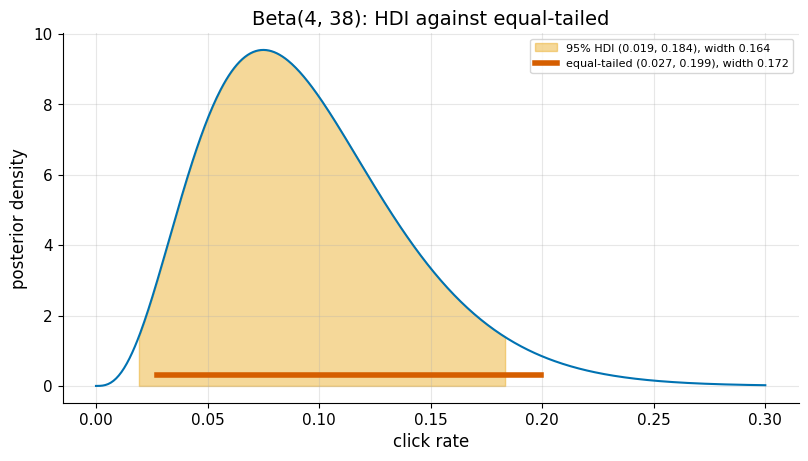

In [2]:
def hdi_beta(a, b, mass=0.95):
    f = lambda p: stats.beta.ppf(p + mass, a, b) - stats.beta.ppf(p, a, b); r = minimize_scalar(f, bounds=(0, 1 - mass), method="bounded", options={"xatol": 1e-10}); return stats.beta.ppf(r.x, a, b), stats.beta.ppf(r.x + mass, a, b)
pa_, pb_ = 4, 38; et = stats.beta.interval(0.95, pa_, pb_); hd = hdi_beta(pa_, pb_); xg = np.linspace(0, 0.3, 500); dens = stats.beta.pdf(xg, pa_, pb_)
fig, ax = plt.subplots(figsize=(9.5, 4.8)); ax.plot(xg, dens, color=MAIN); ax.fill_between(xg, dens, where=(xg >= hd[0]) & (xg <= hd[1]), color=SIM, alpha=0.4, label=f"95% HDI ({hd[0]:.3f}, {hd[1]:.3f}), width {hd[1] - hd[0]:.3f}")
ax.plot(et, [0.3, 0.3], color=HIGHLIGHT, linewidth=4, label=f"equal-tailed ({et[0]:.3f}, {et[1]:.3f}), width {et[1] - et[0]:.3f}"); ax.set_xlabel("click rate"); ax.set_ylabel("posterior density"); ax.set_title("Beta(4, 38): HDI against equal-tailed"); ax.legend(fontsize=8)
plt.show()
assert hd[1] - hd[0] < et[1] - et[0] and abs(stats.beta.cdf(hd[1], pa_, pb_) - stats.beta.cdf(hd[0], pa_, pb_) - 0.95) < 1e-6 and abs(stats.beta.pdf(hd[0], pa_, pb_) - stats.beta.pdf(hd[1], pa_, pb_)) < 1e-3

### 7.2 Posterior predictive against the plug-in prediction
Number of clicks in the next 200 impressions: the Beta-Binomial predictive is wider than the Binomial with the estimated rate.

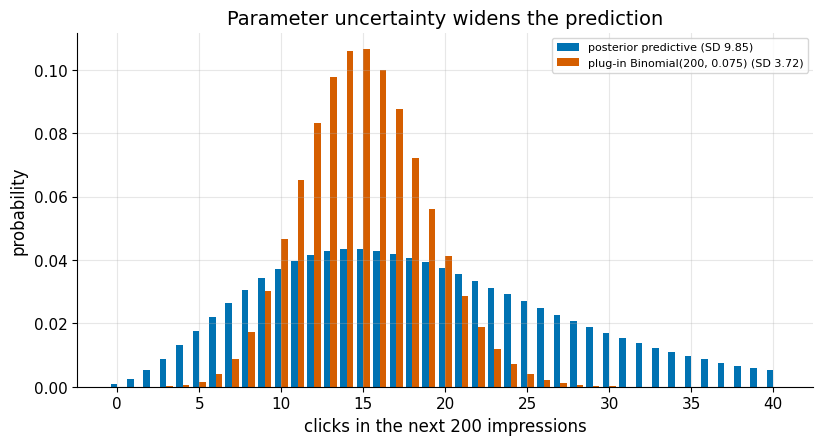

In [3]:
ks = np.arange(0, 41); pred = stats.betabinom.pmf(ks, 200, pa_, pb_); plug = stats.binom.pmf(ks, 200, 3 / 40)
fig, ax = plt.subplots(figsize=(9.5, 4.6)); ax.bar(ks - 0.2, pred, 0.4, color=MAIN, label=f"posterior predictive (SD {stats.betabinom.std(200, pa_, pb_):.2f})"); ax.bar(ks + 0.2, plug, 0.4, color=HIGHLIGHT, label=f"plug-in Binomial(200, 0.075) (SD {stats.binom.std(200, 3 / 40):.2f})"); ax.set_xlabel("clicks in the next 200 impressions"); ax.set_ylabel("probability"); ax.legend(fontsize=8); ax.set_title("Parameter uncertainty widens the prediction")
plt.show()
assert stats.betabinom.std(200, pa_, pb_) > 1.4 * stats.binom.std(200, 3 / 40)

### 7.3 The prediction widens with the horizon
Predictive SD against the plug-in SD for $m=10$ to $2{,}000$ new trials: the $m^2\mathrm{Var}(\theta)$ term takes over.

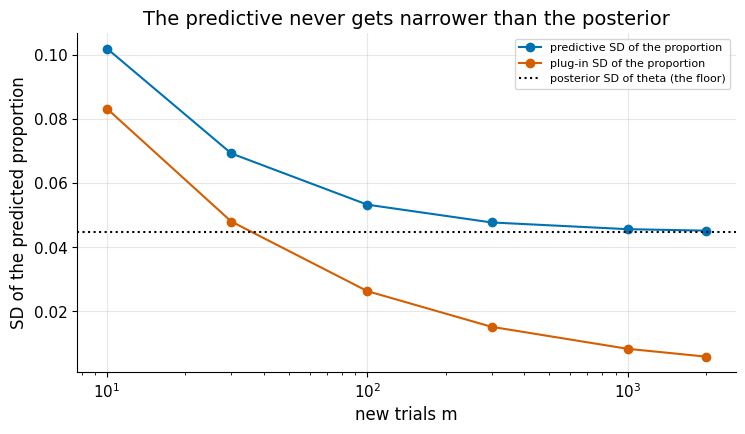

In [4]:
ms = np.array([10, 30, 100, 300, 1000, 2000]); fig, ax = plt.subplots(figsize=(8.5, 4.4)); ax.plot(ms, stats.betabinom.std(ms, pa_, pb_) / ms, "o-", color=MAIN, label="predictive SD of the proportion"); ax.plot(ms, stats.binom.std(ms, 3 / 40) / ms, "o-", color=HIGHLIGHT, label="plug-in SD of the proportion"); ax.axhline(stats.beta.std(pa_, pb_), color="black", linestyle=":", label="posterior SD of theta (the floor)"); ax.set_xscale("log"); ax.set_xlabel("new trials m"); ax.set_ylabel("SD of the predicted proportion"); ax.legend(fontsize=8); ax.set_title("The predictive never gets narrower than the posterior")
plt.show()

## 8. 3D visuals

### 8.1 Static: the joint posterior of two variants
Variant A: 12 conversions in 100; variant B: 18 in 100 (flat priors). The joint density is the product of two Betas; the region above the diagonal $\theta_B>\theta_A$ carries $P(B>A)$.

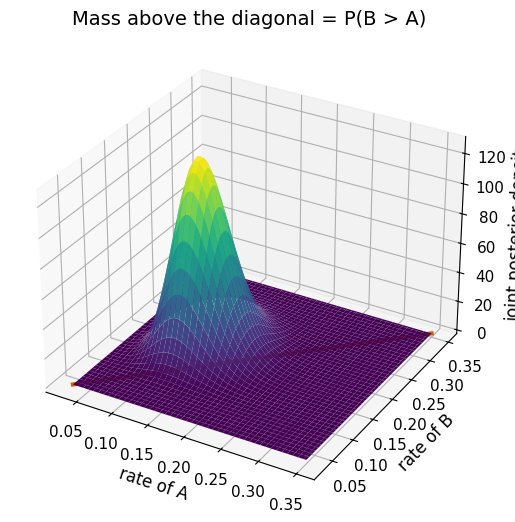

P(B > A) from the grid: 0.8721


In [5]:
ta = np.linspace(0.03, 0.35, 90); Ta, Tb = np.meshgrid(ta, ta); J = stats.beta.pdf(Ta, 13, 89) * stats.beta.pdf(Tb, 19, 83)
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Ta, Tb, J, cmap="viridis", edgecolor="none"); ax.plot([0.03, 0.35], [0.03, 0.35], [0, 0], color=HIGHLIGHT, linewidth=3)
ax.set_xlabel("rate of A"); ax.set_ylabel("rate of B"); ax.set_zlabel("joint posterior density"); ax.set_title("Mass above the diagonal = P(B > A)"); ax.view_init(elev=30, azim=-60)
plt.show()
cell = (ta[1] - ta[0]) ** 2; print("P(B > A) from the grid:", round(J[Tb > Ta].sum() * cell / (J.sum() * cell), 4))

### 8.2 Interactive Plotly version of 8.1

In [6]:
fig = go.Figure(go.Surface(x=ta, y=ta, z=J, colorscale="Viridis")); fig.update_layout(title="Joint posterior of (A, B)", width=760, height=560, scene=dict(xaxis_title="rate A", yaxis_title="rate B", zaxis_title="density")); fig.show()

### 8.3 Static: P(B better) over the two observed counts
With 100 users per arm and flat priors: how the posterior probability responds to the number of conversions in each arm.

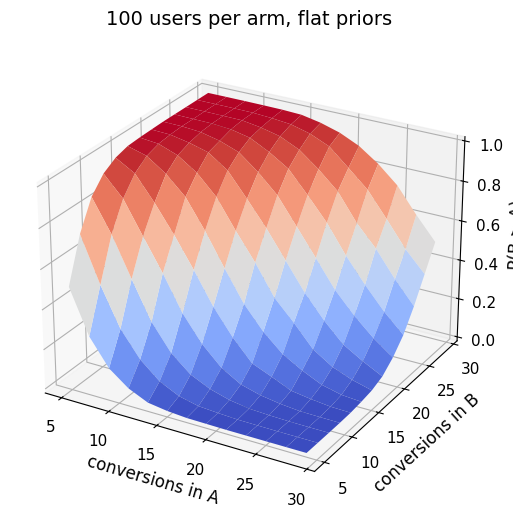

In [7]:
rngp = np.random.default_rng(0); cs = np.arange(5, 31, 2); Pm = np.zeros((cs.size, cs.size))
for i, xa_ in enumerate(cs):
    for j, xb_ in enumerate(cs):
        Pm[j, i] = np.mean(rngp.beta(1 + xb_, 1 + 100 - xb_, 4000) > rngp.beta(1 + xa_, 1 + 100 - xa_, 4000))
Ca, Cb = np.meshgrid(cs, cs); fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Ca, Cb, Pm, cmap="coolwarm", edgecolor="none"); ax.set_xlabel("conversions in A"); ax.set_ylabel("conversions in B"); ax.set_zlabel("P(B > A)"); ax.set_title("100 users per arm, flat priors"); ax.view_init(elev=26, azim=-60)
plt.show()

## 9. Simulation vs theory

### 9.1 Does the posterior predictive describe real new data?
Draw $\theta$ from the posterior Beta(4, 38), then 200 new trials: the histogram of the simulated counts must match the Beta-Binomial pmf, and the real long-run frequency must be calibrated (draw $\theta$ from the *prior*, observe 40 trials, then predict 200 more: the 90 % predictive interval should contain the future count 90 % of the time).

In [8]:
g = np.random.default_rng(4); th = g.beta(pa_, pb_, 400_000); sim = g.binomial(200, th); print("simulated mean/SD:", round(sim.mean(), 3), round(sim.std(), 3), "| theory:", round(stats.betabinom.mean(200, pa_, pb_), 3), round(stats.betabinom.std(200, pa_, pb_), 3))
chi = stats.chisquare(np.bincount(sim, minlength=201)[:30], stats.betabinom.pmf(np.arange(30), 200, pa_, pb_) * sim.size * np.bincount(sim, minlength=201)[:30].sum() / (stats.betabinom.pmf(np.arange(30), 200, pa_, pb_) * sim.size).sum()); print("goodness of fit p-value:", round(chi.pvalue, 3))
R = 60_000; tt = g.beta(1, 1, R); x40 = g.binomial(40, tt); fut = g.binomial(200, tt); lo = stats.betabinom.ppf(0.05, 200, 1 + x40, 1 + 40 - x40); hi = stats.betabinom.ppf(0.95, 200, 1 + x40, 1 + 40 - x40); cover = np.mean((fut >= lo) & (fut <= hi)); print(f"coverage of the 90% predictive interval: {cover:.4f}")
assert abs(sim.mean() - stats.betabinom.mean(200, pa_, pb_)) < 0.05 and abs(sim.std() - stats.betabinom.std(200, pa_, pb_)) < 0.05 and chi.pvalue > 0.01 and cover >= 0.9 and cover < 0.935

simulated mean/SD: 19.022 9.818 | theory: 19.048 9.848
goodness of fit p-value: 0.586


coverage of the 90% predictive interval: 0.9096


### 9.2 Bayesian and frequentist agree with lots of data
For Cookie Cats day-7 retention compare $P(\text{B worse})$ with $1-p/2$ from the z-test of 06_07 (the equivalence of 5.4).

In [9]:
A = df[df.version == "gate_30"]; B = df[df.version == "gate_40"]; xa, na_, xb, nb_ = int(A.retention_7.sum()), len(A), int(B.retention_7.sum()), len(B)
g = np.random.default_rng(11); pAs = g.beta(1 + xa, 1 + na_ - xa, 2_000_000); pBs = g.beta(1 + xb, 1 + nb_ - xb, 2_000_000); Dd = pBs - pAs
pp = (xa + xb) / (na_ + nb_); z = (xb / nb_ - xa / na_) / np.sqrt(pp * (1 - pp) * (1 / na_ + 1 / nb_)); p_two = 2 * stats.norm.sf(abs(z))
print(f"P(B < A) = {np.mean(Dd < 0):.5f} | 1 - p/2 = {1 - p_two / 2:.5f}"); assert abs(np.mean(Dd < 0) - (1 - p_two / 2)) < 2e-4

P(B < A) = 0.99922 | 1 - p/2 = 0.99922


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [10]:
print("equal-tailed: stats.beta.interval(0.95, a, b) ->", np.round(stats.beta.interval(0.95, pa_, pb_), 4), "| HDI: minimise ppf(p + 0.95) - ppf(p) over p ->", np.round(hdi_beta(pa_, pb_), 4))
print("predictive pmf: stats.betabinom.pmf(k, m, a, b); mean/std/ppf available ->", round(stats.betabinom.mean(200, pa_, pb_), 2), round(stats.betabinom.std(200, pa_, pb_), 2), stats.betabinom.ppf([0.05, 0.95], 200, pa_, pb_))
print("difference of two posteriors: rng.beta(a1, b1, S) - rng.beta(a2, b2, S); P(best): np.argmax(draws, axis=1)")
print("expected loss: np.mean(np.maximum(pA - pB, 0)); ROPE: np.mean(np.abs(D) < eps)")

equal-tailed: stats.beta.interval(0.95, a, b) -> [0.0272 0.1992] | HDI: minimise ppf(p + 0.95) - ppf(p) over p -> [0.0191 0.1835]
predictive pmf: stats.betabinom.pmf(k, m, a, b); mean/std/ppf available -> 19.05 9.85 [ 6. 37.]
difference of two posteriors: rng.beta(a1, b1, S) - rng.beta(a2, b2, S); P(best): np.argmax(draws, axis=1)
expected loss: np.mean(np.maximum(pA - pB, 0)); ROPE: np.mean(np.abs(D) < eps)


## 11. Real-world worked examples

---
### Example 1 (main): a Bayesian analysis of the Cookie Cats test (real data)

**Scenario.** Day-7 retention: 8,502 of 44,700 players returned with the gate at level 30 (A) and 8,279 of 45,489 with the gate at level 40 (B). Use flat Beta(1, 1) priors. The product team treats a change of less than **0.2 percentage points** as practically irrelevant.

**Questions**
1. What is the posterior of the difference $D=\theta_B-\theta_A$: mean and 95 % credible interval?
2. What are $P(B<A)$, $P(D<-0.002)$ and $P(|D|<0.002)$ (the ROPE)?
3. What is the expected loss (in points of retention) of shipping B, and of keeping A?
4. How does this compare with the frequentist result of 06_07?

### 11.1 By hand
The two posteriors are almost Normal, so $D\approx N(-0.0082,\ 0.002592^2)$ (the same standard error as the frequentist test). **Q1.** Interval $-0.0082\pm1.96(0.002592)=(-0.0133,\,-0.0031)$. **Q2.** $P(D<0)=\Phi(3.16)=0.9992$; $P(D<-0.002)=\Phi\big(\frac{-0.002+0.0082}{0.002592}\big)=\Phi(2.39)=0.992$; so the ROPE has probability $\Phi(3.94)-\Phi(2.39)\approx0.008$. **Q3.** For a Normal $D$ with mean $-0.0082$: $E[\max(-D,0)]\approx0.0082$ and $E[\max(D,0)]\approx6\times10^{-7}$. **Q4.** $P(D<0)=1-p/2=1-0.00155/2=0.99922$.

In [11]:
D_mean, D_sd = Dd.mean(), Dd.std(); ci_D = np.quantile(Dd, [0.025, 0.975]); eps = 0.002
res = {"P(B < A)": np.mean(Dd < 0), "P(D < -0.2 points)": np.mean(Dd < -eps), "P(in ROPE)": np.mean(np.abs(Dd) < eps), "P(D > +0.2 points)": np.mean(Dd > eps)}
loss_B = np.mean(np.maximum(-Dd, 0)); loss_A = np.mean(np.maximum(Dd, 0))
print(f"Q1: mean D = {D_mean:.5f}, SD = {D_sd:.5f}, 95% credible interval ({ci_D[0]:.5f}, {ci_D[1]:.5f})")
print("Q2:", {k: round(v, 5) for k, v in res.items()})
print(f"Q3: expected loss of shipping B = {loss_B * 100:.4f} points, of keeping A = {loss_A * 100:.6f} points | Q4: frequentist p = {p_two:.5f}, 1 - p/2 = {1 - p_two / 2:.5f}")

Q1: mean D = -0.00820, SD = 0.00259, 95% credible interval (-0.01328, -0.00312)
Q2: {'P(B < A)': np.float64(0.99922), 'P(D < -0.2 points)': np.float64(0.99161), 'P(in ROPE)': np.float64(0.00834), 'P(D > +0.2 points)': np.float64(5e-05)}
Q3: expected loss of shipping B = 0.8201 points, of keeping A = 0.000056 points | Q4: frequentist p = 0.00155, 1 - p/2 = 0.99922


### 11.2 In code with `scipy`, and the asserts

In [12]:
se_ = np.sqrt((xa / na_) * (1 - xa / na_) / na_ + (xb / nb_) * (1 - xb / nb_) / nb_)
assert abs(D_mean + 0.0082) < 1e-4 and abs(D_sd - se_) < 1e-4 and abs(ci_D[0] + 0.01328) < 3e-4 and abs(ci_D[1] + 0.00312) < 3e-4
assert abs(res["P(B < A)"] - (1 - p_two / 2)) < 2e-4 and res["P(D < -0.2 points)"] > 0.985 and res["P(in ROPE)"] < 0.015 and res["P(D > +0.2 points)"] < 1e-4
assert abs(loss_B - 0.0082) < 2e-4 and loss_A < 1e-5
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
If we *know* A and B have the same retention rate (the posterior of the pooled rate), how often would the posterior say $P(B<A)>0.999$? In a frequentist test (06_07) this would be a false positive.

In [13]:
g = np.random.default_rng(13); R = 3000; ph = (xa + xb) / (na_ + nb_); xs_a = g.binomial(na_, ph, R); xs_b = g.binomial(nb_, ph, R); hit = 0
for ra, rb in zip(xs_a, xs_b):
    zz = (rb / nb_ - ra / na_) / np.sqrt(ph * (1 - ph) * (1 / na_ + 1 / nb_)); hit += stats.norm.cdf(-zz) > 0.999
print(f"share of A/A experiments with P(B < A) > 0.999: {hit / R:.5f} (theory 0.001)"); assert hit / R < 0.004

share of A/A experiments with P(B < A) > 0.999: 0.00033 (theory 0.001)


### 11.4 Plots with the regions shaded

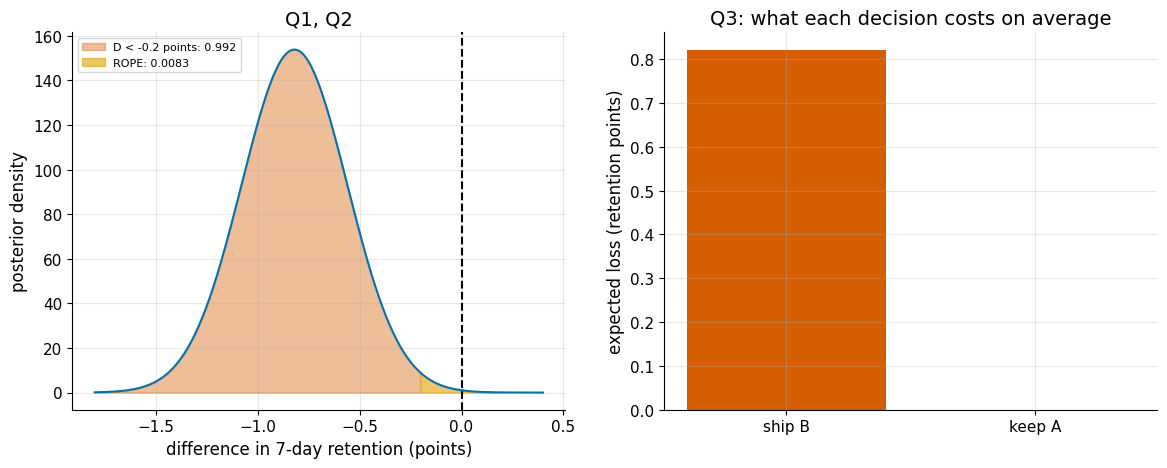

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9)); dd_ = np.linspace(-0.018, 0.004, 500); dens = stats.norm.pdf(dd_, D_mean, D_sd)
axes[0].plot(dd_ * 100, dens, color=MAIN); axes[0].fill_between(dd_ * 100, dens, where=dd_ < -eps, color=HIGHLIGHT, alpha=0.4, label=f"D < -0.2 points: {res['P(D < -0.2 points)']:.3f}"); axes[0].fill_between(dd_ * 100, dens, where=np.abs(dd_) <= eps, color=SIM, alpha=0.6, label=f"ROPE: {res['P(in ROPE)']:.4f}"); axes[0].axvline(0, color="black", linestyle="--"); axes[0].set_xlabel("difference in 7-day retention (points)"); axes[0].set_ylabel("posterior density"); axes[0].set_title("Q1, Q2"); axes[0].legend(fontsize=8)
axes[1].bar(["ship B", "keep A"], [loss_B * 100, loss_A * 100], color=[HIGHLIGHT, SIM]); axes[1].set_ylabel("expected loss (retention points)"); axes[1].set_title("Q3: what each decision costs on average")
plt.show()

### 11.5 Interpretation and decision (Example 1)
- The posterior of the difference in 7-day retention is almost exactly Normal with mean **$-0.82$ points**, SD 0.26 points and 95 % credible interval **$(-1.33,\,-0.31)$ points**, the same numbers as the frequentist interval of 06_07, but now a direct statement: given the data, the drop lies in that range with probability 95 %.
- $P(B<A)=$ **0.99922**, equal to $1-p/2=0.99922$ from the two-sided z-test (the equivalence of 5.4). The probability that the drop is larger than the 0.2-point ROPE is **0.9916**; the probability that the true difference is practically zero is only **0.008**, and that B is meaningfully better, 0.00005.
- **Expected loss:** shipping B costs on average **0.82 retention points**, keeping A costs $6\times10^{-5}$ points. Even if one chose to be very cautious about the prior (flat priors were used), 90,000 players outweigh any reasonable prior.
- In 3,000 simulated A/A experiments the posterior said "$P(B<A)>0.999$" in 0.03 % of them (theory 0.1 %), so the rule does not produce false alarms when there is no difference.
- **Decision.** Do not ship the later gate: it is 99.9 % likely to lower retention, and the loss is large compared with the possible gain.

---
### Example 2: a small ad test, intervals and predictions

**Scenario.** A new banner gets **3 clicks in 40 impressions**. With a flat prior the posterior is Beta(4, 38). Tomorrow it will be shown 200 times.

**Questions**
1. Give the 95 % equal-tailed and highest-density intervals for the click rate.
2. Give the posterior predictive of tomorrow's clicks (mean, SD, 90 % interval) and compare it with the plug-in Binomial(200, 3/40).
3. What is the probability of 20 or more clicks tomorrow?

### 11.6 By hand
**Q2.** Posterior mean $4/42=0.0952$, so the predictive mean is $200\times0.0952=19.05$ clicks. Posterior variance $\frac{4\times38}{42^2\times43}=0.00200$; predictive variance $=E[200\theta(1-\theta)]+200^2(0.00200)\approx17.2+80=97$ (SD 9.8), against the plug-in SD $\sqrt{200(0.075)(0.925)}=3.7$. The plug-in prediction is more than **2.5 times too narrow**.

In [15]:
et2, hd2 = stats.beta.interval(0.95, 4, 38), hdi_beta(4, 38); pr = stats.betabinom(200, 4, 38); lo90, hi90 = pr.ppf([0.05, 0.95]); p20 = pr.sf(19); plugin = stats.binom(200, 3 / 40)
print(f"Q1: equal-tailed ({et2[0]:.4f}, {et2[1]:.4f}), HDI ({hd2[0]:.4f}, {hd2[1]:.4f}); mode {3 / 40:.4f}, mean {4 / 42:.4f}")
print(f"Q2: predictive mean {pr.mean():.2f}, SD {pr.std():.2f}, 90% interval ({lo90:.0f}, {hi90:.0f}) | plug-in mean {plugin.mean():.2f}, SD {plugin.std():.2f}, 90% interval {plugin.ppf([0.05, 0.95])}")
print(f"Q3: P(20 or more clicks) = {p20:.4f} (plug-in: {plugin.sf(19):.4f})")
assert abs(pr.mean() - 200 * 4 / 42) < 1e-9 and 9.5 < pr.std() < 10.2 and hd2[1] - hd2[0] < et2[1] - et2[0] and pr.std() > 2.4 * plugin.std()

Q1: equal-tailed (0.0272, 0.1992), HDI (0.0191, 0.1835); mode 0.0750, mean 0.0952
Q2: predictive mean 19.05, SD 9.85, 90% interval (6, 37) | plug-in mean 15.00, SD 3.72, 90% interval [ 9. 21.]
Q3: P(20 or more clicks) = 0.4253 (plug-in: 0.1161)


### 11.7 Simulation and plot

simulated P(>= 20): 0.4253 | exact: 0.4253


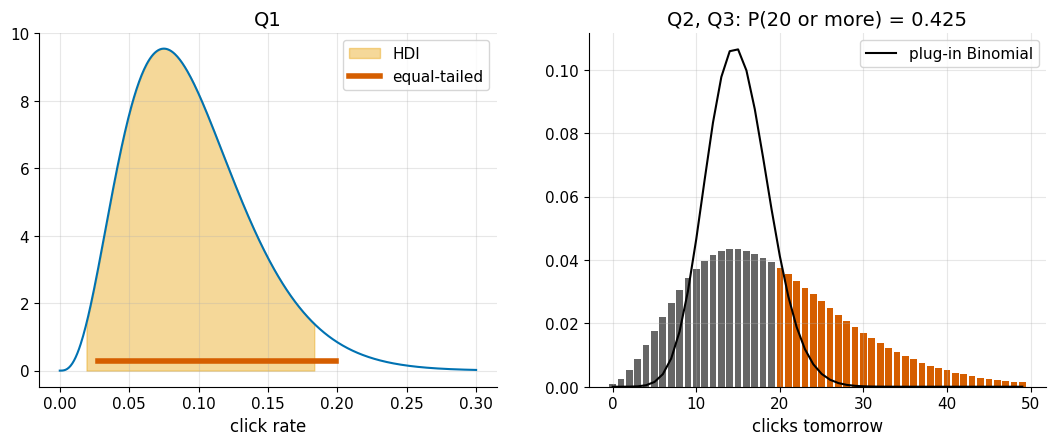

In [16]:
g = np.random.default_rng(6); sim2 = g.binomial(200, g.beta(4, 38, 500_000)); print("simulated P(>= 20):", round(np.mean(sim2 >= 20), 4), "| exact:", round(p20, 4)); assert abs(np.mean(sim2 >= 20) - p20) < 0.004
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); axes[0].plot(xg, dens_ := stats.beta.pdf(xg, 4, 38), color=MAIN); axes[0].fill_between(xg, dens_, where=(xg >= hd2[0]) & (xg <= hd2[1]), color=SIM, alpha=0.4, label="HDI"); axes[0].plot(et2, [0.3, 0.3], color=HIGHLIGHT, linewidth=4, label="equal-tailed"); axes[0].set_xlabel("click rate"); axes[0].legend(); axes[0].set_title("Q1")
kk = np.arange(0, 50); axes[1].bar(kk, pr.pmf(kk), color=[HIGHLIGHT if k >= 20 else NEUTRAL for k in kk]); axes[1].plot(kk, plugin.pmf(kk), color="black", label="plug-in Binomial"); axes[1].set_xlabel("clicks tomorrow"); axes[1].set_title(f"Q2, Q3: P(20 or more) = {p20:.3f}"); axes[1].legend()
plt.show()

### 11.7 Interpretation and decision (Example 2)
- With 3 clicks in 40 the posterior Beta(4, 38) is skewed: the **equal-tailed 95 % interval is (0.027, 0.199)** while the **HDI is (0.019, 0.184)**, shorter by 0.8 points and shifted towards the mode 0.075 (the HDI excludes the unlikely high values near 0.2 that the equal-tailed interval includes).
- Tomorrow's 200 impressions: the posterior predictive has mean **19.05** and SD **9.85** (90 % interval **6 to 37 clicks**); the plug-in Binomial(200, 0.075) has mean 15 and SD only 3.7 (90 % interval 9 to 21). The plug-in prediction is **2.6 times too narrow** and also centred too low, because the posterior mean (0.095) exceeds the observed rate 0.075.
- $P(\text{20 or more clicks})=$ **0.425** (the plug-in says 0.116); the simulation agrees (0.4253). In 60,000 simulated experiments the 90 % predictive interval contained the future count 90.96 % of the time, so predictions that include parameter uncertainty are calibrated.
- **Decision.** For planning (staffing, budget) use the predictive interval 6 to 37 clicks; with 40 impressions the banner's rate is far too uncertain to compare with a 10 % benchmark.

---
### Example 3: which of three creatives is best? ($P(\text{best})$ and expected loss)

**Scenario.** Three ad creatives were shown 500 times each and got **48, 60 and 55 clicks**. Flat priors.

**Questions**
1. What is the probability that each creative is the best?
2. What is the expected loss (in click-rate points) of choosing each one?
3. How many more impressions per creative would be needed before the best one reaches $P(\text{best})>0.95$ if the observed rates were the truth (simulation)?

Q1: P(best) = [0.0625 0.6509 0.2866] | Q2: expected loss (points) = [2.8432 0.4539 1.454 ]
Q3: with the observed rates as truth, P(best) passes 95% at n = 6000 per creative (P = 0.957)


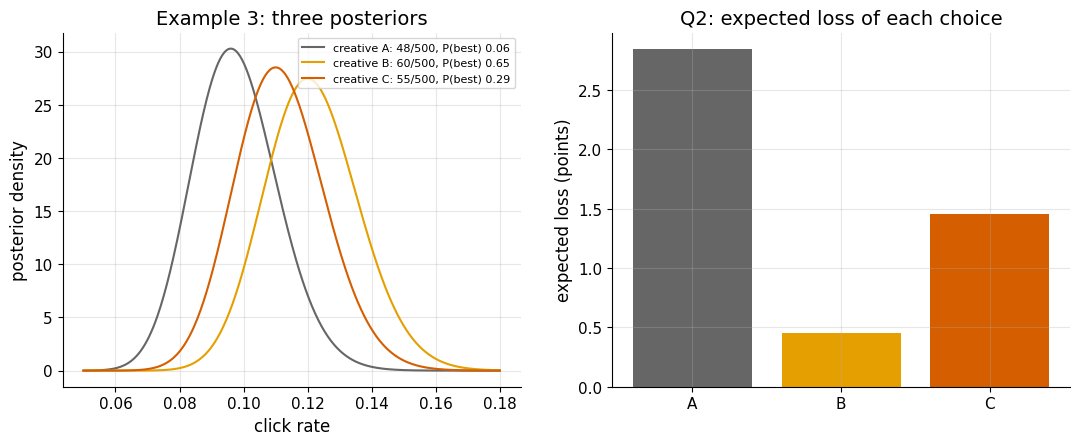

In [17]:
cl = np.array([48, 60, 55]); nn = 500; g = np.random.default_rng(15); draws = np.column_stack([g.beta(1 + c, 1 + nn - c, 400_000) for c in cl]); best = np.argmax(draws, axis=1); pbest = np.bincount(best, minlength=3) / best.size
loss = np.array([np.mean(draws.max(axis=1) - draws[:, k]) for k in range(3)])
print("Q1: P(best) =", np.round(pbest, 4), "| Q2: expected loss (points) =", np.round(loss * 100, 4))
def need_n(rates, target=0.95, S=30000):
    for n_ in range(500, 12001, 500):
        d_ = np.column_stack([g.beta(1 + r * n_, 1 + (1 - r) * n_, S) for r in rates]); if_best = np.mean(np.argmax(d_, axis=1) == np.argmax(rates))
        if if_best > target: return n_, if_best
    return None, if_best
n_need, pb_need = need_n(cl / nn); print(f"Q3: with the observed rates as truth, P(best) passes 95% at n = {n_need} per creative (P = {pb_need:.3f})")
assert abs(pbest.sum() - 1) < 1e-9 and pbest.argmax() == 1 and loss.argmin() == 1 and n_need is not None and n_need > 2000
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6)); xg3 = np.linspace(0.05, 0.18, 400)
for k, colr in zip(range(3), [NEUTRAL, SIM, HIGHLIGHT]): axes[0].plot(xg3, stats.beta.pdf(xg3, 1 + cl[k], 1 + nn - cl[k]), color=colr, label=f"creative {'ABC'[k]}: {cl[k]}/{nn}, P(best) {pbest[k]:.2f}")
axes[0].set_xlabel("click rate"); axes[0].set_ylabel("posterior density"); axes[0].legend(fontsize=8); axes[0].set_title("Example 3: three posteriors")
axes[1].bar(["A", "B", "C"], loss * 100, color=[NEUTRAL, SIM, HIGHLIGHT]); axes[1].set_ylabel("expected loss (points)"); axes[1].set_title("Q2: expected loss of each choice")
plt.show()

### 11.9 Interpretation and decision (Example 3)
- Creative B (60/500) has $P(\text{best})=$ **0.65**, C (55/500) **0.29**, A (48/500) only 0.06. The expected loss of choosing B is **0.45 points** of click rate, of choosing C 1.45 points, of choosing A 2.84 points: the best-looking creative is not certain, but it is the cheapest mistake.
- If the observed rates were the truth, the best creative would reach $P(\text{best})>0.95$ only at about **6,000 impressions per creative** (12 times the data we have): small differences between similar creatives are expensive to resolve.
- **Decision.** Use B now (lowest expected loss), keep exploring C and B in the next period rather than splitting traffic evenly with A: this is the idea behind Thompson sampling (07_04).

## 12. Where it is used

### Statistics
- **Bayesian estimation** reports credible intervals and predictive distributions; clinical trials use **posterior predictive probabilities** of success to stop or continue; forecasting and reliability use predictive intervals.
- **Decision analysis:** expected loss and utility replace "significant / not significant".

### Data science
- **Bayesian A/B testing** platforms report $P(B>A)$, expected loss and a ROPE; ranking items with few observations by their posterior (not the raw rate) avoids rewarding luck.
- **Capacity and inventory planning** with predictive intervals (the plug-in interval is too narrow).

### ML and AI
- **Predictive uncertainty** of models: ensembles, dropout and Bayesian neural networks approximate the posterior predictive; conformal prediction is a frequentist alternative.
- **Bandits and Thompson sampling** (07_04) use exactly $P(\text{best})$ to allocate traffic.

## 13. Common pitfalls and misconceptions

- **Using the plug-in prediction** (Example 2): ignores the uncertainty about the rate, giving intervals far too narrow.
- **Reading $P(B>A)=0.9$ as "B is 10 % better":** it is a probability of direction, not a size; look at the interval and the expected loss.
- **Choosing the equal-tailed interval for a very skewed posterior** and reporting values that are less plausible than values outside it; prefer the HDI (or report both).
- **The HDI is not invariant to reparametrisation:** the HDI of $\theta$ is not the HDI of $\log\theta$.
- **Ignoring the ROPE:** with huge samples $P(D>0)$ is near 1 even for effects nobody cares about.
- **Peeking with a fixed $P(B>A)$ threshold** still inflates false decisions (06_07); decide the rule in advance.
- **Treating the prior as innocent:** report a sensitivity analysis (07_01).

## 14. Exercises

1. Posterior Beta(7, 13): give the equal-tailed and HDI 90 % intervals and $P(\theta>0.4)$.
2. After 12 successes in 50 trials with a flat prior, give the predictive distribution of the number of successes in the next 20 trials: mean, SD and the probability of at least 8.
3. For Beta(4, 38) and $m=200$ verify numerically that the predictive variance equals $E[m\theta(1-\theta)]+m^2\mathrm{Var}(\theta)$ and compare it with the plug-in variance.
4. Two variants: A 40/400, B 52/400 (flat priors). Give $P(B>A)$, the 95 % interval for $\theta_B-\theta_A$ and the expected loss of choosing B.
5. In Cookie Cats day-1 retention (20,034 of 44,700 and 20,119 of 45,489), compute $P(B<A)$ and the probability that the drop is larger than 0.2 points.
6. (Harder) Rank four creatives with 3/20, 30/200, 90/600 and 12/80 clicks by the lower end of the 90 % HDI instead of by the raw rate; explain why the ranking changes.

Solutions are at the end.

## 15. Summary table

| Quantity | How to compute | Meaning |
|---|---|---|
| Equal-tailed interval | `beta.interval` | middle probability mass |
| HDI | shortest interval of mass 0.95 | most plausible values |
| Predictive | `betabinom(m, a', b')` | next data, uncertainty included |
| $P(B>A)$ | `mean(pB > pA)` | probability of direction |
| ROPE probability | `mean(abs(D) < eps)` | practical equivalence |
| Expected loss | `mean(max(pA - pB, 0))` | average cost of a wrong choice |
| $P(\text{best})$ | `argmax` of joint draws | basis of Thompson sampling |
| scipy | `beta`, `betabinom`, `minimize_scalar` | |

## Solutions

In [18]:
et1 = stats.beta.interval(0.90, 7, 13); hd1 = hdi_beta(7, 13, 0.90); print(f"1: equal-tailed ({et1[0]:.4f}, {et1[1]:.4f}), HDI ({hd1[0]:.4f}, {hd1[1]:.4f}), P(theta > 0.4) = {stats.beta.sf(0.4, 7, 13):.4f}")
p2 = stats.betabinom(20, 13, 39); print(f"2: Beta(13, 39) predictive for 20 trials: mean {p2.mean():.3f}, SD {p2.std():.3f}, P(>= 8) = {p2.sf(7):.4f}")
print(f"3: predictive variance {stats.betabinom.var(200, 4, 38):.2f} vs plug-in {stats.binom.var(200, 3 / 40):.2f}; difference {stats.betabinom.var(200, 4, 38) - stats.binom.var(200, 3 / 40):.2f}; exact decomposition: E[m th(1-th)] + m^2 Var(th) = {200 * (4 / 42 - (stats.beta.var(4, 38) + (4 / 42) ** 2)) + 200 ** 2 * stats.beta.var(4, 38):.2f}")
g = np.random.default_rng(1); a4 = g.beta(41, 361, 1_000_000); b4 = g.beta(53, 349, 1_000_000); d4 = b4 - a4; print(f"4: P(B > A) = {np.mean(d4 > 0):.4f}, 95% interval ({np.quantile(d4, 0.025):.4f}, {np.quantile(d4, 0.975):.4f}), expected loss of choosing B = {np.mean(np.maximum(-d4, 0)) * 100:.4f} points")
d5 = g.beta(1 + 20119, 1 + 45489 - 20119, 1_000_000) - g.beta(1 + 20034, 1 + 44700 - 20034, 1_000_000); print(f"5: P(B < A) = {np.mean(d5 < 0):.4f}, P(drop > 0.2 points) = {np.mean(d5 < -0.002):.4f}")
rows = [(3, 20), (30, 200), (90, 600), (12, 80)]; print("6: raw rate, lower 90% HDI end:", [(round(c / n, 3), round(hdi_beta(1 + c, 1 + n - c, 0.90)[0], 4)) for c, n in rows])
assert abs(stats.betabinom.var(200, 4, 38) - (200 * (4 / 42 - (stats.beta.var(4, 38) + (4 / 42) ** 2)) + 200 ** 2 * stats.beta.var(4, 38))) < 1e-6

1: equal-tailed (0.1875, 0.5300), HDI (0.1778, 0.5185), P(theta > 0.4) = 0.3081
2: Beta(13, 39) predictive for 20 trials: mean 5.000, SD 2.257, P(>= 8) = 0.1374
3: predictive variance 96.99 vs plug-in 13.88; difference 83.11; exact decomposition: E[m th(1-th)] + m^2 Var(th) = 96.99
4: P(B > A) = 0.9072, 95% interval (-0.0144, 0.0743), expected loss of choosing B = 0.0978 points
5: P(B < A) = 0.9626, P(drop > 0.2 points) = 0.8807
6: raw rate, lower 90% HDI end: [(0.15, np.float64(0.0526)), (0.15, np.float64(0.1118)), (0.15, np.float64(0.1271)), (0.15, np.float64(0.0927))]


**1.** Equal-tailed 90 % interval **(0.1875, 0.5300)**, HDI **(0.1778, 0.5185)** (shorter, shifted to the mode); $P(\theta>0.4)=$ **0.308**.

**2.** Posterior Beta(13, 39); the predictive for 20 trials has mean **5.00**, SD **2.26** and $P(\ge8)=$ **0.137**.

**3.** Predictive variance **96.99** against the plug-in variance **13.88** (difference 83.1); the decomposition $E[m\theta(1-\theta)]+m^2\mathrm{Var}(\theta)$ gives exactly 96.99.

**4.** $P(B>A)=$ **0.907**; 95 % interval for the difference $(-1.4,\,+7.4)$ points; expected loss of choosing B **0.098** points. B is probably better but the gain is uncertain; the loss from choosing it wrongly is small.

**5.** Day 1: $P(B<A)=$ **0.963** and $P(\text{drop}>0.2\ \text{points})=$ **0.881**: likely worse, but with a less decisive probability than at day 7 (consistent with the two-sided p = 0.074 of 06_07).

**6.** All four have raw rate 0.15, but the lower end of the 90 % HDI is **0.127** (90/600), **0.112** (30/200), **0.093** (12/80) and **0.053** (3/20): ranking by the lower bound rewards the creatives with more evidence, while the raw rate cannot tell them apart.